#HIT140 Foundations of Data Science · Assessment 3 (Group Project).

# Objective  – Predicting FIFA World Cup 2026 Results with Linear Regression

## 1. Project title and research questions

* **RQ 2.1** – Using only information available before kick-off, how accurately can a linear regression model predict the goal difference** of a World Cup 2026 match (Team A goals − Team B goals)?
* **RQ 2.2** – Using only pre-match information, how accurately can a regression model predict the **number of goals scored by one team** in a match, given that goals are non-negative whole numbers?
* For both: does the model beat a naive baseline that always predicts the training average, and is a simple model preferable to a more complex one?

In [29]:
import json, re, subprocess, sys, warnings, zipfile, filecmp, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import sklearn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, PoissonRegressor, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 140
np.random.seed(SEED)
DATA, RAW, FIG, OUT = Path("data"), Path("data/raw"), Path("figures"), Path("outputs")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# One consistent, colour-blind-checked palette; recessive grid and axes
COL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "grey": "#9a9893", "ink": "#0b0b0b", "ink2": "#52514e"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight", "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#9a9893", "legend.frameon": False})

SECTIONS_RUN = []          # each section registers itself; used by the execution check in §15
def section(n): SECTIONS_RUN.append(n)
section(3)
for lib in (np, pd, matplotlib, scipy, statsmodels, sklearn):
    print(f"{lib.__name__:12s}{lib.__version__}")
print("Python", sys.version.split()[0])

numpy       2.1.3
pandas      2.2.3
matplotlib  3.10.0
scipy       1.16.3
statsmodels 0.15.0
sklearn     1.6.1
Python 3.13.16


## 4. Loading and validating both datasets
Column roles are declared **once** here: identifiers, target, and the eight predictors. Every later step uses these lists, so the predictor count cannot drift.

In [30]:
section(4)
reg21 = pd.read_csv(DATA / "/content/drive/MyDrive/SHAHNAWAZ ALAM/Data Analytics/Objective 2/data/reg21_dataset.csv")
reg22 = pd.read_csv(DATA / "/content/drive/MyDrive/SHAHNAWAZ ALAM/Data Analytics/Objective 2/data/reg22_dataset.csv")

ID21, TARGET21 = ["match_id", "date", "stage", "team1", "team2"], "goal_diff"
X21 = ["elo_diff", "host_diff", "rest_days_diff", "form_gd_diff", "h2h_gd", "wc_exp_diff", "tourn_gd_diff", "travel_km_diff"]
ID22, TARGET22 = ["row_id", "match_id", "date", "stage", "team", "opponent"], "goals"
X22 = ["elo_diff", "is_host", "rest_days", "attack_form10", "opp_defence_form10",
       "tourn_goals_so_far", "opp_tourn_conceded_so_far", "knockout"]

def overview(df, name, ids, target, preds):
    unassigned = set(df.columns) - set(ids) - {target} - set(preds)
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns | {len(preds)} predictors | "
          f"target = '{target}' | unassigned columns: {sorted(unassigned) or 'none'}")
    info = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                         "unique": df.nunique(),
                         "role": ["ID/info" if c in ids else "TARGET" if c == target else "predictor" for c in df.columns]})
    return info

display(overview(reg21, "Task 2.1", ID21, TARGET21, X21))
display(reg21.head(3))
display(overview(reg22, "Task 2.2", ID22, TARGET22, X22))
display(reg22.head(4))

Task 2.1: 104 rows x 14 columns | 8 predictors | target = 'goal_diff' | unassigned columns: none


,dtype,missing,unique,role
match_id,int64,0,104,ID/info
date,object,0,34,ID/info
stage,object,0,7,ID/info
team1,object,0,48,ID/info
team2,object,0,48,ID/info
elo_diff,float64,0,103,predictor
host_diff,int64,0,3,predictor
rest_days_diff,int64,0,9,predictor
form_gd_diff,float64,0,45,predictor
h2h_gd,float64,0,41,predictor


,match_id,date,stage,team1,team2,elo_diff,host_diff,rest_days_diff,form_gd_diff,h2h_gd,wc_exp_diff,tourn_gd_diff,travel_km_diff,goal_diff
0,1,2026-06-11,Group stage,Mexico,South Africa,316.400,1,2,0.700,1.250,51,0,0.000,2
1,2,2026-06-11,Group stage,South Korea,Czech Republic,77.400,0,1,-1.000,-1.333,35,0,0.000,1
2,3,2026-06-18,Group stage,Czech Republic,South Africa,123.000,0,0,1.000,0.000,-6,1,202.000,0


Task 2.2: 208 rows x 15 columns | 8 predictors | target = 'goals' | unassigned columns: none


,dtype,missing,unique,role
row_id,object,0,208,ID/info
match_id,int64,0,104,ID/info
date,object,0,34,ID/info
stage,object,0,7,ID/info
team,object,0,48,ID/info
opponent,object,0,48,ID/info
elo_diff,float64,0,206,predictor
is_host,int64,0,2,predictor
rest_days,int64,0,10,predictor
attack_form10,float64,0,32,predictor


,row_id,match_id,date,stage,team,opponent,elo_diff,is_host,rest_days,attack_form10,opp_defence_form10,tourn_goals_so_far,opp_tourn_conceded_so_far,knockout,goals
0,1_A,1,2026-06-11,Group stage,Mexico,South Africa,316.400,1,7,1.600,1.000,0,0,0,2
1,1_B,1,2026-06-11,Group stage,South Africa,Mexico,-316.400,0,5,1.500,0.400,0,0,0,0
2,2_A,2,2026-06-11,Group stage,South Korea,Czech Republic,77.400,0,8,1.500,0.900,0,0,0,2
3,2_B,2,2026-06-11,Group stage,Czech Republic,South Korea,-77.400,0,7,2.200,1.200,0,0,0,1


In [31]:
# ---- structural checks -------------------------------------------------------------
CHECKS = {}   # name -> (status, detail); reported in section 15
def record(name, ok, detail):
    CHECKS[name] = ("PASS" if ok else "FAIL", detail)
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: {detail}")

record("Task 2.1 has 104 match rows", len(reg21) == 104 and reg21.match_id.is_unique,
       f"{len(reg21)} rows, {reg21.match_id.nunique()} unique match_id")
record("Task 2.2 has 208 team-match rows", len(reg22) == 208 and reg22.row_id.is_unique,
       f"{len(reg22)} rows, {reg22.row_id.nunique()} unique row_id")
pairs = reg22.groupby("match_id").size()
record("Exactly two team rows per match (2.2)", (pairs == 2).all() and set(pairs.index) == set(reg21.match_id),
       f"rows per match: {pairs.value_counts().to_dict()}; same 104 match_ids as 2.1: {set(pairs.index) == set(reg21.match_id)}")
record("Exactly 8 predictors per task", len(X21) == 8 and len(X22) == 8, f"2.1: {len(X21)}, 2.2: {len(X22)}")
record("No missing values", reg21.isna().sum().sum() == 0 and reg22.isna().sum().sum() == 0,
       f"2.1 missing = {reg21.isna().sum().sum()}, 2.2 missing = {reg22.isna().sum().sum()}")
record("No duplicate records", not reg21.duplicated().any() and not reg22.duplicated().any()
       and not reg21.duplicated(["date", "team1", "team2"]).any() and not reg22.duplicated(["match_id", "team"]).any(),
       "no repeated rows, no repeated (date, team1, team2) match, no team twice in one match")

# each match's two rows in 2.2 must be the same pairing as in 2.1, mirrored
m = reg22.merge(reg21[["match_id", "team1", "team2"]], on="match_id")
ok_pair = ((m.team == m.team1) & (m.opponent == m.team2)) | ((m.team == m.team2) & (m.opponent == m.team1))
record("2.2 team/opponent pairs agree with 2.1", ok_pair.all(), f"{ok_pair.sum()}/208 rows consistent")

[PASS] Task 2.1 has 104 match rows: 104 rows, 104 unique match_id
[PASS] Task 2.2 has 208 team-match rows: 208 rows, 208 unique row_id
[PASS] Exactly two team rows per match (2.2): rows per match: {2: 104}; same 104 match_ids as 2.1: True
[PASS] Exactly 8 predictors per task: 2.1: 8, 2.2: 8
[PASS] No missing values: 2.1 missing = 0, 2.2 missing = 0
[PASS] No duplicate records: no repeated rows, no repeated (date, team1, team2) match, no team twice in one match
[PASS] 2.2 team/opponent pairs agree with 2.1: 208/208 rows consistent


In [32]:
# ---- targets checked against the raw source (openfootball JSON) ------------------------
NAME_MAP = {"USA": "United States", "Bosnia & Herzegovina": "Bosnia and Herzegovina"}
raw = json.load(open(RAW / "/content/drive/MyDrive/SHAHNAWAZ ALAM/Data Analytics/Objective 2/data/raw/worldcup2026.json", encoding="utf-8"))["matches"]
src = []
for i, mm in enumerate(raw, start=1):
    sc = mm["score"]; final = sc.get("et") or sc["ft"]          # extra time included, shoot-out excluded
    off = int(re.search(r"UTC([+-]\d+)", mm["time"]).group(1))
    kickoff_utc = pd.Timestamp(f"{mm['date']} {mm['time'].split()[0]}") - pd.Timedelta(hours=off)
    src.append({"match_id": i, "src_team1": NAME_MAP.get(mm["team1"], mm["team1"]),
                "src_team2": NAME_MAP.get(mm["team2"], mm["team2"]), "g1": final[0], "g2": final[1],
                "kickoff_utc": kickoff_utc, "venue": mm["ground"], "extra_time": "et" in sc, "shootout": "p" in sc})
src = pd.DataFrame(src)
chk = reg21.merge(src, on="match_id")
names_ok = ((chk.team1 == chk.src_team1) & (chk.team2 == chk.src_team2)).all()
record("Task 2.1 target = Team A goals - Team B goals", names_ok and (chk.goal_diff == chk.g1 - chk.g2).all(),
       f"{(chk.goal_diff == chk.g1 - chk.g2).sum()}/104 goal differences match the raw scores; team names match: {names_ok}")
chk22 = reg22.merge(src, on="match_id")
own = np.where(chk22.team == chk22.src_team1, chk22.g1, chk22.g2)
record("Task 2.2 target = goals scored by that team", (chk22.goals == own).all(),
       f"{(chk22.goals == own).sum()}/208 team goal counts match the raw scores")
w = reg22.pivot_table(index="match_id", columns=reg22.row_id.str[-1], values="goals")
record("2.1 and 2.2 targets are mutually consistent",
       (reg21.set_index("match_id").goal_diff == (w["A"] - w["B"])).all(), "goal_diff = goals(row A) - goals(row B) for all 104 matches")
print(f"\nMatches decided in extra time: {src.extra_time.sum()} (of which {src.shootout.sum()} went to penalties; "
      "shoot-out goals are not counted, so those enter as draws).")

teams21 = set(reg21.team1) | set(reg21.team2); teams22 = set(reg22.team)
print(f"Teams: {len(teams21)} in 2.1, {len(teams22)} in 2.2, identical sets: {teams21 == teams22}")

[PASS] Task 2.1 target = Team A goals - Team B goals: 104/104 goal differences match the raw scores; team names match: True
[PASS] Task 2.2 target = goals scored by that team: 208/208 team goal counts match the raw scores
[PASS] 2.1 and 2.2 targets are mutually consistent: goal_diff = goals(row A) - goals(row B) for all 104 matches

Matches decided in extra time: 9 (of which 4 went to penalties; shoot-out goals are not counted, so those enter as draws).
Teams: 48 in 2.1, 48 in 2.2, identical sets: True


## 5. Data dictionaries and predictor audit
### 5.1 Data dictionary
Every predictor is computed from results dated **strictly before** the match. Running tournament totals are updated only after a match has been recorded.

### 5.2 Shared predictor concepts
The brief allows at most four explanatory variables to be shared between the two tasks. A variable is counted as shared when it measures the **same concept**, even if it is coded differently. For example, `host_diff` and `is_host` both measure host status.

In [34]:
CONCEPT = {  # predictor -> underlying concept
    "elo_diff": "strength gap (Elo)", "host_diff": "host status", "is_host": "host status",
    "rest_days_diff": "rest days", "rest_days": "rest days", "form_gd_diff": "recent goal-difference form",
    "h2h_gd": "head-to-head record", "wc_exp_diff": "World Cup experience", "tourn_gd_diff": "tournament goal difference",
    "travel_km_diff": "travel distance", "attack_form10": "own attacking form", "opp_defence_form10": "opponent defensive form",
    "tourn_goals_so_far": "own tournament goals", "opp_tourn_conceded_so_far": "opponent tournament goals conceded",
    "knockout": "knockout stage"}
shared = sorted({CONCEPT[c] for c in X21} & {CONCEPT[c] for c in X22})
record("At most 4 shared predictor concepts", len(shared) <= 4, f"{len(shared)} shared: {shared}")
record("Every predictor is documented with pre-match availability",
       all(any(c in v for v in dictionary.variable) for c in X21 + X22) and dictionary["pre-match availability"].notna().all(),
       "all 16 predictor columns appear in the data dictionary with a pre-match availability statement")

[PASS] At most 4 shared predictor concepts: 3 shared: ['host status', 'rest days', 'strength gap (Elo)']
[PASS] Every predictor is documented with pre-match availability: all 16 predictor columns appear in the data dictionary with a pre-match availability statement


### 5.3 Predictor audit: independent recomputation from the raw files
A dictionary entry only states that a variable is pre-match. To check the claim, the cells below recompute **every predictor** directly from the raw files, using only matches dated *before* each fixture, and compare the results with the supplied CSVs. Any use of future information would appear as a mismatch.

In [35]:
res = pd.read_csv(RAW / "/content/drive/MyDrive/SHAHNAWAZ ALAM/Data Analytics/Objective 2/data/raw/international_results.csv", parse_dates=["date"]).dropna(subset=["home_score", "away_score"])
res = res.sort_values("date", kind="stable").reset_index(drop=True)
long = pd.concat([res.assign(team=res.home_team, opp=res.away_team, gf=res.home_score, ga=res.away_score),
                  res.assign(team=res.away_team, opp=res.home_team, gf=res.away_score, ga=res.home_score)])
long = long[["date", "team", "opp", "gf", "ga", "tournament"]].sort_values("date", kind="stable")
hist = {t: g for t, g in long.groupby("team")}
def before(team, date):            # a team's matches strictly before `date`
    g = hist[team]; return g[g.date < date]

# --- Elo, rebuilt from 1872 with the eloratings.net rules; the rating stored for a match is the one BEFORE it
def k_factor(t):
    if t == "FIFA World Cup": return 60
    if t in {"UEFA Euro", "Copa América", "African Cup of Nations", "AFC Asian Cup", "Gold Cup",
             "Confederations Cup", "CONCACAF Championship", "OFC Nations Cup"}: return 50
    if "qualification" in t or "Nations League" in t: return 40
    return 20 if t == "Friendly" else 30
elo, elo_pre = {}, {}
for r in res.itertuples(index=False):
    eh, ea = elo.get(r.home_team, 1500.0), elo.get(r.away_team, 1500.0)
    elo_pre[(r.date, r.home_team)], elo_pre[(r.date, r.away_team)] = eh, ea
    gd = r.home_score - r.away_score
    mult = 1 if abs(gd) <= 1 else 1.5 if abs(gd) == 2 else 1.75 + (abs(gd) - 3) / 8
    exp_h = 1 / (1 + 10 ** (-(eh - ea + (0 if r.neutral else 100)) / 400))
    delta = k_factor(r.tournament) * mult * ((gd > 0) + 0.5 * (gd == 0) - exp_h)
    elo[r.home_team], elo[r.away_team] = eh + delta, ea - delta

# --- venues, hosts and travel from the fixture file
VENUE_XY = {"Mexico City": (19.3029, -99.1505), "Guadalajara (Zapopan)": (20.6817, -103.4627),
    "Monterrey (Guadalupe)": (25.6694, -100.2446), "Toronto": (43.6332, -79.4186), "Vancouver": (49.2768, -123.1120),
    "Seattle": (47.5952, -122.3316), "San Francisco Bay Area (Santa Clara)": (37.4030, -121.9700),
    "Los Angeles (Inglewood)": (33.9535, -118.3392), "Dallas (Arlington)": (32.7473, -97.0945),
    "Houston": (29.6847, -95.4107), "Kansas City": (39.0489, -94.4839), "Atlanta": (33.7554, -84.4008),
    "Miami (Miami Gardens)": (25.9580, -80.2389), "Boston (Foxborough)": (42.0909, -71.2643),
    "Philadelphia": (39.9008, -75.1675), "New York/New Jersey (East Rutherford)": (40.8135, -74.0745)}
VENUE_COUNTRY = {"Mexico City": "Mexico", "Guadalajara (Zapopan)": "Mexico", "Monterrey (Guadalupe)": "Mexico",
                 "Toronto": "Canada", "Vancouver": "Canada"}
def km(a, b):
    (p1, l1), (p2, l2) = [(math.radians(x), math.radians(y)) for x, y in (a, b)]
    h = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin((l2 - l1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h))
fx = reg21[["match_id", "team1", "team2", "goal_diff"]].merge(src[["match_id", "g1", "g2", "venue", "kickoff_utc"]], on="match_id")
fx["date"] = pd.to_datetime(reg21.date)
fx = fx.sort_values(["date", "match_id"])

In [36]:
def team_features(team, opp, row, state):
    d = row.date
    h = before(team, d); last10 = h.tail(10); prev = state["venue"].get(team)
    return {"elo": elo_pre[(d, team)],
            "host": int(team in {"United States", "Mexico", "Canada"} and VENUE_COUNTRY.get(row.venue, "United States") == team),
            "rest": min((d - h.date.iloc[-1]).days, 14),
            "gf10": last10.gf.mean(), "ga10": last10.ga.mean(),
            "h2h": (lambda x: 0.0 if x.empty else (x.gf - x.ga).mean())(h[h.opp == opp].tail(10)),
            "wcexp": int((h.tournament == "FIFA World Cup").sum()),
            "t_gf": state["gf"].get(team, 0), "t_ga": state["ga"].get(team, 0),
            "travel": 0.0 if prev is None else km(VENUE_XY[prev], VENUE_XY[row.venue])}

state = {"gf": {}, "ga": {}, "venue": {}}
re21, re22 = [], []
for row in fx.itertuples(index=False):
    a = team_features(row.team1, row.team2, row, state); b = team_features(row.team2, row.team1, row, state)
    re21.append({"match_id": row.match_id, "elo_diff": a["elo"] - b["elo"], "host_diff": a["host"] - b["host"],
                 "rest_days_diff": a["rest"] - b["rest"], "form_gd_diff": (a["gf10"] - a["ga10"]) - (b["gf10"] - b["ga10"]),
                 "h2h_gd": a["h2h"], "wc_exp_diff": a["wcexp"] - b["wcexp"],
                 "tourn_gd_diff": (a["t_gf"] - a["t_ga"]) - (b["t_gf"] - b["t_ga"]), "travel_km_diff": a["travel"] - b["travel"]})
    for s, o, tm, op in [(a, b, row.team1, row.team2), (b, a, row.team2, row.team1)]:
        re22.append({"match_id": row.match_id, "team": tm, "elo_diff": s["elo"] - o["elo"], "is_host": s["host"],
                     "rest_days": s["rest"], "attack_form10": s["gf10"], "opp_defence_form10": o["ga10"],
                     "tourn_goals_so_far": s["t_gf"], "opp_tourn_conceded_so_far": o["t_ga"]})
    # update the running tournament state only AFTER the match
    for tm, gf, ga in [(row.team1, row.g1, row.g2), (row.team2, row.g2, row.g1)]:
        state["gf"][tm] = state["gf"].get(tm, 0) + gf; state["ga"][tm] = state["ga"].get(tm, 0) + ga
        state["venue"][tm] = row.venue

def compare(recomputed, original, key, cols, tol):
    j = original.merge(pd.DataFrame(recomputed), on=key, suffixes=("", "_re"))
    return pd.Series({c: int((np.abs(j[c] - j[c + "_re"]) <= tol[c] if c in tol else j[c] == j[c + "_re"]).sum()) for c in cols})
tol21 = {"elo_diff": 0.051, "form_gd_diff": 0.0005, "h2h_gd": 0.0005, "travel_km_diff": 0.51}
tol22 = {"elo_diff": 0.051, "attack_form10": 0.0005, "opp_defence_form10": 0.0005}
agree21 = compare(re21, reg21, ["match_id"], X21, tol21)
agree22 = compare(re22, reg22, ["match_id", "team"], [c for c in X22 if c != "knockout"], tol22)
agree22["knockout"] = int((reg22.knockout == reg22.stage.ne("Group stage").astype(int)).sum())
audit = pd.concat([agree21.rename("rows matching (of 104)"), agree22.rename("rows matching (of 208)")], axis=1)
display(audit)
record("All 16 predictors reproduce from pre-match data only", (agree21 == 104).all() and (agree22 == 208).all(),
       "every value recomputed from matches dated before kick-off (rounding tolerance only)")

,rows matching (of 104),rows matching (of 208)
elo_diff,104.000,208.000
host_diff,104.000,NaN
rest_days_diff,104.000,NaN
form_gd_diff,104.000,NaN
h2h_gd,104.000,NaN
wc_exp_diff,104.000,NaN
tourn_gd_diff,104.000,NaN
travel_km_diff,104.000,NaN
is_host,NaN,208.000
rest_days,NaN,208.000


[PASS] All 16 predictors reproduce from pre-match data only: every value recomputed from matches dated before kick-off (rounding tolerance only)


In [37]:
# The submitted CSVs must also be reproducible end-to-end by the provenance script (writes to data/rebuilt/, originals untouched)
out = subprocess.run([sys.executable, "/content/drive/MyDrive/SHAHNAWAZ ALAM/Data Analytics/Objective 2/src/build_datasets.py", "data/rebuilt"], capture_output=True, text=True)
print(out.stdout.strip().splitlines()[0])
same = all(filecmp.cmp(DATA / f, DATA / "rebuilt" / f, shallow=False) for f in ["/content/drive/MyDrive/SHAHNAWAZ ALAM/Data Analytics/Objective 2/data/reg21_dataset.csv", "/content/drive/MyDrive/SHAHNAWAZ ALAM/Data Analytics/Objective 2/data/reg22_dataset.csv"])
record("Datasets rebuild identically from raw files", out.returncode == 0 and same, "src/build_datasets.py output is byte-identical to data/*.csv")

Score cross-check: 104/104 matches agree between the two sources
[PASS] Datasets rebuild identically from raw files: src/build_datasets.py output is byte-identical to data/*.csv


## 6. Data cleaning and preprocessing


In [38]:
section(6)
for df in (reg21, reg22):
    df["date"] = pd.to_datetime(df["date"])
kick = src.set_index("match_id").kickoff_utc
reg21["kickoff_utc"] = reg21.match_id.map(kick); reg22["kickoff_utc"] = reg22.match_id.map(kick)
reg21 = reg21.sort_values("kickoff_utc").reset_index(drop=True)
reg22 = reg22.sort_values(["kickoff_utc", "row_id"]).reset_index(drop=True)
print("Note: match_id follows the order of the source file (grouped by group), not time; "
      "e.g. match_id 3 was played on", reg21.loc[reg21.match_id == 3, "date"].dt.date.iloc[0])

# ---- range checks: values must lie in plausible, documented ranges ----
rng = pd.DataFrame({
    "rule": ["goal_diff in [-10,10]", "goals >= 0 and integer", "rest days in [0,14]", "host flags in {-1,0,1}/{0,1}",
             "knockout in {0,1}", "|elo_diff| < 800", "form averages >= 0", "tournament totals >= 0"],
    "violations": [int((reg21.goal_diff.abs() > 10).sum()), int(((reg22.goals < 0) | (reg22.goals % 1 != 0)).sum()),
                   int((~reg22.rest_days.between(0, 14)).sum() + (reg21.rest_days_diff.abs() > 14).sum()),
                   int((~reg21.host_diff.isin([-1, 0, 1])).sum() + (~reg22.is_host.isin([0, 1])).sum()),
                   int((~reg22.knockout.isin([0, 1])).sum()),
                   int((reg21.elo_diff.abs() >= 800).sum() + (reg22.elo_diff.abs() >= 800).sum()),
                   int(((reg22.attack_form10 < 0) | (reg22.opp_defence_form10 < 0)).sum()),
                   int(((reg22.tourn_goals_so_far < 0) | (reg22.opp_tourn_conceded_so_far < 0)).sum())]})
display(rng)
record("All values within valid ranges", rng.violations.sum() == 0, f"{rng.violations.sum()} violations")

Note: match_id follows the order of the source file (grouped by group), not time; e.g. match_id 3 was played on 2026-06-18


,rule,violations
0,"goal_diff in [-10,10]",0
1,goals >= 0 and integer,0
2,"rest days in [0,14]",0
3,"host flags in {-1,0,1}/{0,1}",0
4,"knockout in {0,1}",0
5,|elo_diff| < 800,0
6,form averages >= 0,0
7,tournament totals >= 0,0


[PASS] All values within valid ranges: 0 violations


In [39]:
# ---- unusual observations: flag with the 1.5 x IQR rule, then investigate (not delete) ----
def iqr_flags(s):
    q1, q3 = s.quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return ((s < lo) | (s > hi)).sum()
flags = pd.DataFrame({"2.1 (of 104)": reg21[X21 + [TARGET21]].apply(iqr_flags)}).join(
        pd.DataFrame({"2.2 (of 208)": reg22[X22 + [TARGET22]].apply(iqr_flags)}), how="outer").fillna("–")
display(flags)
print("Largest winning margins (target 2.1):")
display(reg21.loc[reg21.goal_diff.abs().nlargest(6).index, ["date", "stage", "team1", "team2", "goal_diff", "elo_diff"]])
print("Rows at the 14-day rest cap:", int((reg22.rest_days == 14).sum()),
      "| pairs that had never met (h2h_gd set to 0):", int(((reg21.h2h_gd == 0)).sum()))

,2.1 (of 104),2.2 (of 208)
attack_form10,–,1.000
elo_diff,0.000,0.000
form_gd_diff,0.000,–
goal_diff,0.000,–
goals,–,3.000
h2h_gd,8.000,–
host_diff,13.000,–
is_host,–,13.000
knockout,–,0.000
opp_defence_form10,–,0.000


Largest winning margins (target 2.1):


,date,stage,team1,team2,goal_diff,elo_diff
8,2026-06-14,Group stage,Germany,Curaçao,6,399.100
26,2026-06-18,Group stage,Canada,Qatar,6,285.400
44,2026-06-23,Group stage,Portugal,Uzbekistan,5,221.500
60,2026-06-26,Group stage,Senegal,Iraq,5,163.600
11,2026-06-14,Group stage,Sweden,Tunisia,4,32.500
32,2026-06-20,Group stage,Netherlands,Sweden,4,187.700


Rows at the 14-day rest cap: 4 | pairs that had never met (h2h_gd set to 0): 40


In [40]:
TEST_START = pd.Timestamp("2026-07-02")
dev21, test21 = reg21[reg21.date < TEST_START].copy(), reg21[reg21.date >= TEST_START].copy()
dev22, test22 = reg22[reg22.date < TEST_START].copy(), reg22[reg22.date >= TEST_START].copy()
split = pd.DataFrame({
    "matches": [dev21.match_id.nunique(), test21.match_id.nunique()],
    "2.1 rows": [len(dev21), len(test21)], "2.2 rows": [len(dev22), len(test22)],
    "share of matches": [len(dev21) / 104, len(test21) / 104],
    "first date": [dev21.date.min().date(), test21.date.min().date()], "last date": [dev21.date.max().date(), test21.date.max().date()],
    "stages": [", ".join(dev21.stage.value_counts().index), ", ".join(test21.stage.value_counts().index)]},
    index=["development (train/tune)", "test (held out)"])
display(split)
no_leak = (set(dev22.match_id).isdisjoint(test22.match_id) and set(dev21.match_id).isdisjoint(test21.match_id)
           and dev21.date.max() < test21.date.min() and dev22.groupby("match_id").size().eq(2).all()
           and test22.groupby("match_id").size().eq(2).all())
record("No match split across partitions; test strictly later", no_leak,
       f"dev {len(dev21)} matches / {len(dev22)} rows; test {len(test21)} matches / {len(test22)} rows; "
       f"last dev date {dev21.date.max().date()} < first test date {test21.date.min().date()}")

,matches,2.1 rows,2.2 rows,share of matches,first date,last date,stages
development (train/tune),82,82,164,0.788,2026-06-11,2026-07-01,"Group stage, Round of 32"
test (held out),22,22,44,0.212,2026-07-02,2026-07-19,"Round of 16, Round of 32, Quarter-final, Semi-..."


[PASS] No match split across partitions; test strictly later: dev 82 matches / 164 rows; test 22 matches / 44 rows; last dev date 2026-07-01 < first test date 2026-07-02


## 7. Exploratory analysis – Task 2.1 (goal difference)
The descriptive statistics use all 104 matches. The eight predictors were fixed **before** this exploration, so looking at the full data here does not influence model choice. Model selection uses the development set only.

In [41]:
section(7)
def describe(df, cols):
    d = df[cols].agg(["mean", "median", "std", "min", "max"]).T
    d.columns = ["mean", "median", "SD", "min", "max"]; return d
desc21 = describe(reg21, X21 + [TARGET21]); display(desc21)
res21 = np.sign(reg21.goal_diff).map({1: "Team A win", 0: "Draw", -1: "Team B win"})
freq21 = pd.concat({"stage": reg21.stage.value_counts(), "result": res21.value_counts(),
                    "host_diff": reg21.host_diff.value_counts().sort_index()}, axis=0).rename("count")
display(freq21.to_frame())

,mean,median,SD,min,max
elo_diff,52.935,51.750,223.214,-496.300,565.200
host_diff,0.067,0.000,0.349,-1.000,1.000
rest_days_diff,0.087,0.000,1.521,-8.000,5.000
form_gd_diff,0.220,0.200,1.288,-2.900,2.600
h2h_gd,-0.004,0.000,1.362,-5.000,5.333
wc_exp_diff,12.692,9.500,43.698,-99.000,112.000
tourn_gd_diff,0.519,0.000,3.791,-13.000,8.000
travel_km_diff,-60.481,0.000,"1,212.878","-4,029.000","2,315.000"
goal_diff,0.481,0.000,2.024,-4.000,6.000


count
stage     Group stage               72
          Round of 32               16
          Round of 16                8
          Quarter-final              4
          Semi-final                 2
          Match for third place      1
          Final                      1
result    Team A win                50
          Team B win                30
          Draw                      24
host_diff -1                         3
          0                         91
          1                         10

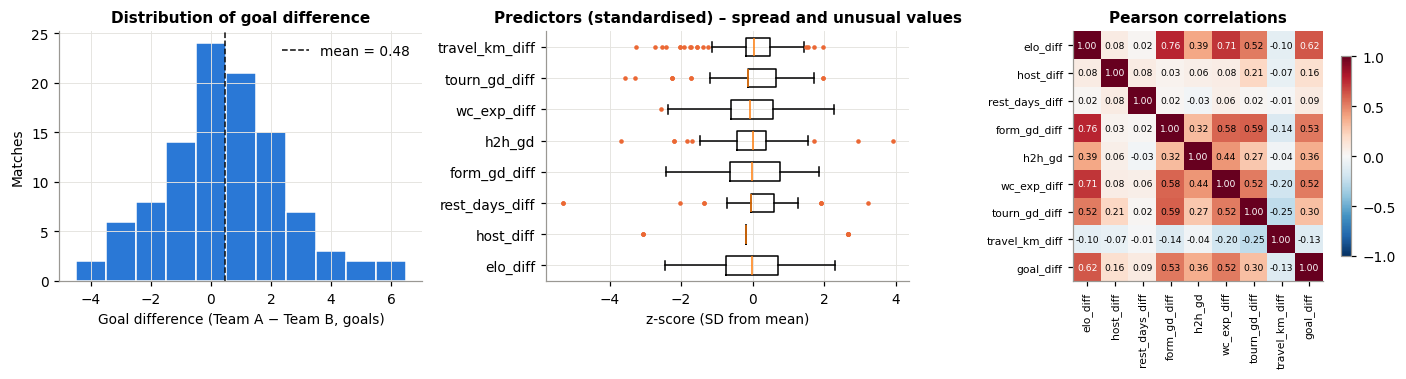

Correlation of each predictor with goal_diff:


,r
elo_diff,0.618
form_gd_diff,0.529
wc_exp_diff,0.517
h2h_gd,0.360
tourn_gd_diff,0.301
host_diff,0.160
travel_km_diff,-0.126
rest_days_diff,0.094


In [42]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
bins = np.arange(reg21.goal_diff.min() - .5, reg21.goal_diff.max() + 1.5)
ax[0].hist(reg21.goal_diff, bins=bins, color=COL["blue"], edgecolor="white")
ax[0].axvline(reg21.goal_diff.mean(), color=COL["ink"], ls="--", lw=1, label=f"mean = {reg21.goal_diff.mean():.2f}")
ax[0].set(title="Distribution of goal difference", xlabel="Goal difference (Team A − Team B, goals)", ylabel="Matches"); ax[0].legend()
z = (reg21[X21] - reg21[X21].mean()) / reg21[X21].std()
ax[1].boxplot([z[c] for c in X21], orientation="horizontal", tick_labels=X21, widths=.6, flierprops=dict(marker="o", ms=3, mfc=COL["orange"], mec="none"))
ax[1].set(title="Predictors (standardised) – spread and unusual values", xlabel="z-score (SD from mean)")
cm = reg21[X21 + [TARGET21]].corr()
im = ax[2].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[2].set_xticks(range(len(cm)), cm.columns, rotation=90, fontsize=7); ax[2].set_yticks(range(len(cm)), cm.columns, fontsize=7)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax[2].text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(cm.iloc[i, j]) > .6 else "black")
ax[2].set_title("Pearson correlations"); ax[2].grid(False); fig.colorbar(im, ax=ax[2], shrink=.8)
fig.tight_layout(); fig.savefig(FIG / "eda21_overview.png"); plt.show()
print("Correlation of each predictor with goal_diff:"); display(cm[TARGET21].drop(TARGET21).sort_values(key=abs, ascending=False).to_frame("r"))

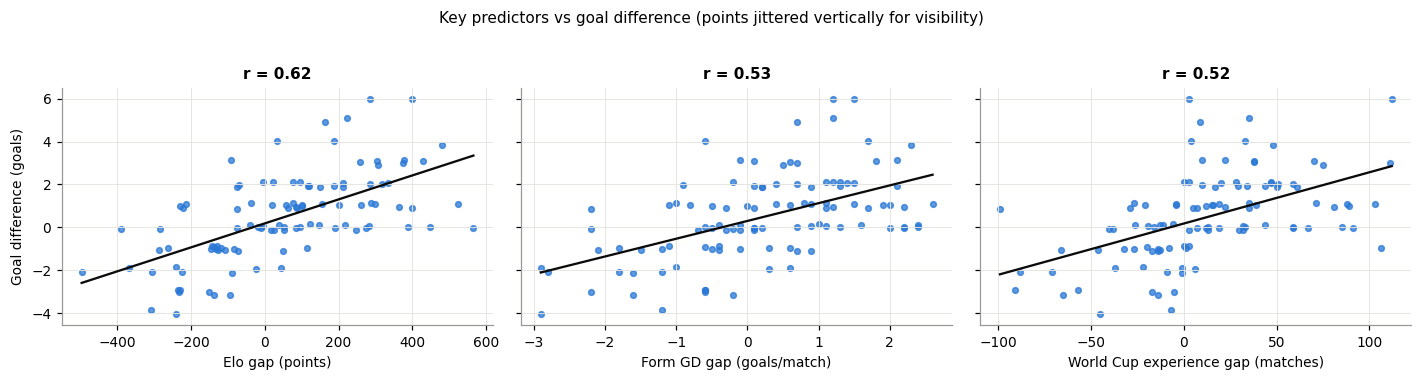

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for a, c, lab in zip(ax, ["elo_diff", "form_gd_diff", "wc_exp_diff"],
                     ["Elo gap (points)", "Form GD gap (goals/match)", "World Cup experience gap (matches)"]):
    a.scatter(reg21[c], reg21.goal_diff + np.random.default_rng(1).uniform(-.15, .15, 104), s=14, color=COL["blue"], alpha=.75)
    b1, b0 = np.polyfit(reg21[c], reg21.goal_diff, 1); xs = np.linspace(reg21[c].min(), reg21[c].max(), 50)
    a.plot(xs, b0 + b1 * xs, color=COL["ink"], lw=1.5)
    a.set(xlabel=lab, title=f"r = {reg21[c].corr(reg21.goal_diff):.2f}")
ax[0].set_ylabel("Goal difference (goals)")
fig.suptitle("Key predictors vs goal difference (points jittered vertically for visibility)", y=1.03, fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "eda21_scatter.png"); plt.show()

**What the plots show and why it matters.**

* **Distribution of goal difference.** It is centred slightly above zero (mean 0.48, SD 2.02) and ranges from −4 to +6.
  * Team A won 50 matches, Team B won 30, and 24 ended level.
  * The positive average follows from how FIFA names the first team. That team is often the seeded or stronger side, so a model needs an intercept.
  * The distribution is roughly symmetric, with a few long blowouts on the right. This is acceptable for linear regression, but those blowouts will produce the largest errors.
* **Correlations with goal difference.** The strongest are the Elo gap (r = 0.62), recent goal-difference form (0.53) and World Cup experience (0.52). Head-to-head record (0.36) and tournament goal difference (0.30) are weaker. Host status, rest and travel are close to zero.
* **Correlations between predictors.** The heatmap shows that the three strongest predictors are strongly correlated with each other, because all three measure team quality. In a multiple regression they will **share** credit, so individual coefficients may look small or non-significant even when the model as a whole predicts well.
* **Scatterplots.** The relationships are roughly linear, with wide scatter. A straight-line model is reasonable, but a large share of variation will remain unexplained, as expected in football.
* **Correlation is not causation.** For example, World Cup experience correlates with winning mainly because experienced nations are strong nations.

## 8. Task 2.1 – baseline and competing models
| Model | Purpose |
|---|---|
| **Baseline (training mean)** | Always predicts the average goal difference of the training matches. Any useful model must beat it. |
| **OLS linear regression** | The core method of the unit. It finds the straight-line combination of the 8 predictors that minimises squared error, and its coefficients are directly interpretable. |
| **Ridge regression** | OLS with a penalty that shrinks coefficients towards zero. With 82 matches and correlated predictors, this can reduce overfitting. The penalty strength α is tuned by cross-validation. |
| **Random forest** | An average of many decision trees, able to capture non-linear effects and interactions. It tests whether a flexible model finds structure that the linear models miss. Its tree depth (`min_samples_leaf`) and features per split are tuned. |

**Selection rule (fixed before looking at the test set).** On the development matches, run 5-fold cross-validation repeated 5 times. Tuning happens **inside** each training fold, so the scores are honest. Choose the model with the lowest mean RMSE. If a **simpler** model's mean RMSE is within one standard error of the best, choose the simpler one. Simplicity order: baseline < OLS < Ridge < random forest.

In [44]:
section(8)
def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "R2": r2_score(y, p)}

ALPHAS = np.logspace(-2, 3, 26)
def tuned(est, grid):
    # returns a 'fit' function: tunes hyper-parameters with match-grouped 5-fold CV on the data it is given
    def fit(X, y, g):
        gs = GridSearchCV(est, grid, cv=GroupKFold(5, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error")
        return gs.fit(X, y, groups=g).best_estimator_
    return fit
plain = lambda est: (lambda X, y, g: clone(est).fit(X, y))

class ClippedAtZero(BaseEstimator, RegressorMixin):
    # OLS whose predictions are clipped at 0 - evaluated as a SEPARATE prediction strategy (Task 2.2)
    def fit(self, X, y): self.m_ = LinearRegression().fit(X, y); return self
    def predict(self, X): return np.clip(self.m_.predict(X), 0, None)

MODELS21 = {
    "Baseline (training mean)": plain(DummyRegressor(strategy="mean")),
    "OLS linear regression": plain(LinearRegression()),
    "Ridge regression": tuned(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": ALPHAS}),
    "Random forest": tuned(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                           {"min_samples_leaf": [3, 6, 10], "max_features": [0.5, 1.0]}),
}

def repeated_cv(models, X, y, groups, repeats=5, k=5):
    rows = []
    for rep in range(repeats):
        for fold, (tr, te) in enumerate(GroupKFold(k, shuffle=True, random_state=SEED + rep).split(X, y, groups)):
            for name, fit in models.items():
                est = fit(X.iloc[tr], y.iloc[tr], groups[tr])
                rows.append({"model": name, "rep": rep, "fold": fold, **metrics(y.iloc[te], est.predict(X.iloc[te]))})
    cv = pd.DataFrame(rows)
    s = cv.groupby("model", sort=False).agg(MAE=("MAE", "mean"), RMSE=("RMSE", "mean"), RMSE_SE=("RMSE", "sem"), R2=("R2", "mean"))
    return cv, s

def choose(summary, order):
    best = summary.RMSE.idxmin(); limit = summary.loc[best, "RMSE"] + summary.loc[best, "RMSE_SE"]
    for m in order:                      # simplest first
        if summary.loc[m, "RMSE"] <= limit: return m, best
    return best, best

Xd21, yd21, gd21 = dev21[X21], dev21[TARGET21], dev21.match_id.values
cv21, cvsum21 = repeated_cv(MODELS21, Xd21, yd21, gd21)
cvsum21.insert(0, "n dev matches", len(dev21))
display(cvsum21)
SELECTED21, BEST_CV21 = choose(cvsum21, list(MODELS21))
print(f"Lowest CV RMSE: {BEST_CV21}.  Selected by the one-SE simplicity rule: {SELECTED21}")

,n dev matches,MAE,RMSE,RMSE_SE,R2
model,,,,,
Baseline (training mean),82,1.634,2.068,0.086,-0.099
OLS linear regression,82,1.353,1.691,0.053,0.149
Ridge regression,82,1.326,1.653,0.058,0.241
Random forest,82,1.287,1.610,0.061,0.257


Lowest CV RMSE: Random forest.  Selected by the one-SE simplicity rule: Ridge regression


**Development-set comparison (5×5 cross-validation, 82 matches).**

* **Every model beats the baseline clearly** (CV RMSE 2.07 for the baseline vs 1.61–1.69 for the others).
* **The random forest had the lowest CV RMSE (1.61).** Ridge (1.65) is within one standard error of it (SE = 0.06), so the pre-specified simplicity rule selects **Ridge regression**. Plain OLS (1.69) lies just outside that band.
* **Why Ridge does better than OLS here:** with only 82 matches and correlated quality measures, shrinking the coefficients reduces their instability. This decision is fixed **before** the test set is used.

## 9. Task 2.1 – evaluation on held-out matches and diagnostics
### 9.1 Test-set performance
Every model is refitted on all 82 development matches, with tuning done on those matches only, and then predicts the 22 test matches. The metrics, in goals:
* **MAE** – the average size of the error. For example, an MAE of 1.2 means predictions miss the true margin by 1.2 goals on average.
* **RMSE** – like MAE, but large misses count more, because errors are squared before averaging.
* **R²** – the share of the variation in the test matches' goal differences that the model explains. It can be negative on a test set, which means the model does worse than simply predicting the test-set average.

In [45]:
section(9)
def fit_all(models, Xd, yd, gd):
    return {name: fit(Xd, yd, gd) for name, fit in models.items()}
fitted21 = fit_all(MODELS21, Xd21, yd21, gd21)
pred21 = {n: m.predict(test21[X21]) for n, m in fitted21.items()}
test_tab21 = pd.DataFrame({n: metrics(test21[TARGET21], p) for n, p in pred21.items()}).T
test_tab21["n test matches"] = len(test21)
test_tab21["selected"] = ["Yes" if n == SELECTED21 else "" for n in test_tab21.index]
display(test_tab21)
print("Tuned hyper-parameters: Ridge alpha =", round(fitted21["Ridge regression"][-1].alpha, 3),
      "| RF", {k: v for k, v in fitted21["Random forest"].get_params().items() if k in ("min_samples_leaf", "max_features")})

# Uncertainty: bootstrap the 22 test matches to get a 95% interval for (baseline RMSE - selected RMSE)
def boot_gain(y, p_model, p_base, n=5000, seed=SEED):
    rng = np.random.default_rng(seed); y, p_model, p_base = map(np.asarray, (y, p_model, p_base))
    idx = rng.integers(0, len(y), (n, len(y)))
    rm = np.sqrt(((y[idx] - p_model[idx]) ** 2).mean(1)); rb = np.sqrt(((y[idx] - p_base[idx]) ** 2).mean(1))
    return np.percentile(rb - rm, [2.5, 50, 97.5]), (rb - rm > 0).mean()
ci21, share21 = boot_gain(test21[TARGET21], pred21[SELECTED21], pred21["Baseline (training mean)"])
print(f"RMSE improvement of {SELECTED21} over baseline: {ci21[1]:.3f} goals, 95% bootstrap CI [{ci21[0]:.3f}, {ci21[2]:.3f}]; "
      f"improvement > 0 in {share21:.0%} of resamples")

# Practical read-out: does the sign of the prediction call the winner?
p_sel = pred21[SELECTED21]; y_t = test21[TARGET21].values
decisive = y_t != 0
winner_acc21 = (np.sign(p_sel[decisive]) == np.sign(y_t[decisive])).mean()
print(f"Of the {decisive.sum()} test matches with a winner after extra time, the selected model's sign picked the winner in "
      f"{(np.sign(p_sel[decisive]) == np.sign(y_t[decisive])).sum()} ({winner_acc21:.0%}).")

,MAE,RMSE,R2,n test matches,selected
Baseline (training mean),1.466,1.768,-0.166,22,
OLS linear regression,1.251,1.542,0.112,22,
Ridge regression,1.243,1.553,0.099,22,Yes
Random forest,1.069,1.365,0.305,22,


Tuned hyper-parameters: Ridge alpha = 15.849 | RF {'max_features': 0.5, 'min_samples_leaf': 10}
RMSE improvement of Ridge regression over baseline: 0.221 goals, 95% bootstrap CI [-0.085, 0.486]; improvement > 0 in 92% of resamples
Of the 20 test matches with a winner after extra time, the selected model's sign picked the winner in 15 (75%).


In [46]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 9.2 Interpreting the OLS model (fitted on the development set)
Prediction and explanation are different questions. The table below describes **associations** in the 82 development matches. The coefficients are not causal effects. Standard errors are HC3-robust, which stays valid even if the error variance is not constant.

In [47]:
ols21 = sm.OLS(yd21, sm.add_constant(Xd21)).fit(cov_type="HC3")
coef21 = pd.DataFrame({"coef": ols21.params, "95% CI low": ols21.conf_int()[0], "95% CI high": ols21.conf_int()[1], "p-value": ols21.pvalues})
coef21["std. coef (per SD)"] = coef21.coef * pd.concat([pd.Series({"const": np.nan}), Xd21.std()])
display(coef21)
print(f"R² = {ols21.rsquared:.3f}, adjusted R² = {ols21.rsquared_adj:.3f}, n = {int(ols21.nobs)}")
vif21 = pd.Series([variance_inflation_factor(sm.add_constant(Xd21).values, i + 1) for i in range(8)], index=X21, name="VIF")
display(vif21.to_frame().T)

,coef,95% CI low,95% CI high,p-value,std. coef (per SD)
const,0.232,-0.164,0.629,0.251,NaN
elo_diff,0.003,-0.000,0.006,0.076,0.680
host_diff,1.066,-0.104,2.236,0.074,0.387
rest_days_diff,0.086,-0.150,0.322,0.474,0.141
form_gd_diff,0.373,-0.134,0.879,0.149,0.491
h2h_gd,0.047,-0.214,0.308,0.722,0.062
wc_exp_diff,0.008,-0.006,0.022,0.267,0.356
tourn_gd_diff,-0.049,-0.200,0.103,0.528,-0.170
travel_km_diff,0.000,-0.000,0.000,0.886,0.028


R² = 0.459, adjusted R² = 0.400, n = 82


,elo_diff,host_diff,rest_days_diff,form_gd_diff,h2h_gd,wc_exp_diff,tourn_gd_diff,travel_km_diff
VIF,3.322,1.153,1.036,2.964,1.285,2.369,1.882,1.117


### 9.3 Regression diagnostics
The panels show, in order: actual vs predicted on the **test** matches; residuals vs fitted values (development fit), which checks linearity and constant variance; the residual distribution with a normal Q–Q plot; and Cook's distance, which flags influential matches. The 4/n rule of thumb marks matches worth investigating.

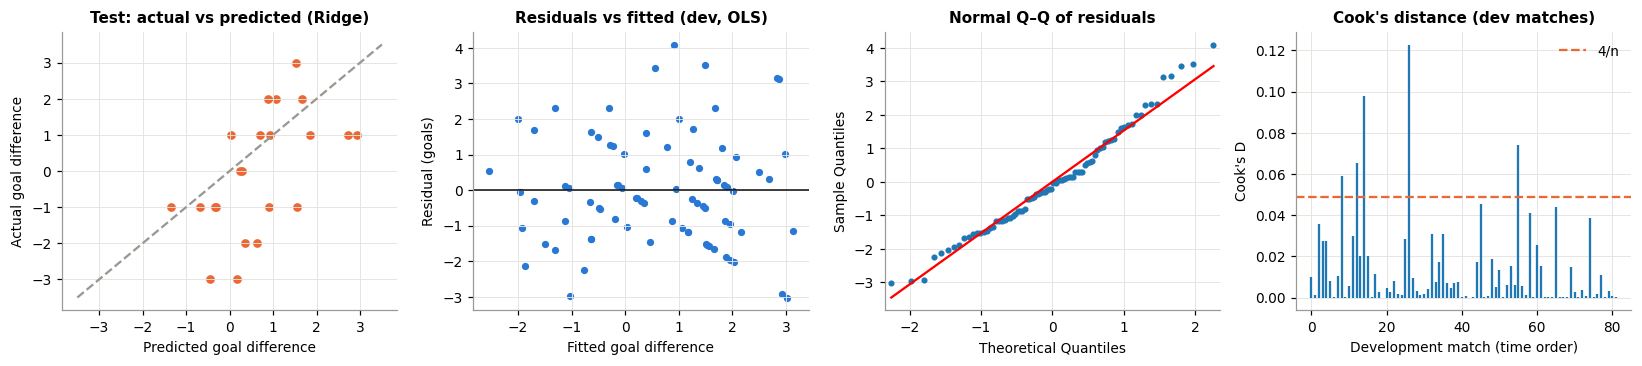

,date,team1,team2,goal_diff,elo_diff,cooks
26,2026-06-18,Canada,Qatar,6,285.400,0.123
14,2026-06-15,Saudi Arabia,Uruguay,0,-283.800,0.098
55,2026-06-25,Ecuador,Germany,1,-76.500,0.074
12,2026-06-15,Spain,Cape Verde,0,565.200,0.065
8,2026-06-14,Germany,Curaçao,6,399.100,0.059


,elo_diff,form_gd_diff,h2h_gd
all dev matches,0.003,0.373,0.047
without influential,0.003,0.357,0.036


Shapiro–Wilk p (residual normality): 0.17 | largest |residual|: 4.1


In [48]:
infl21 = sm.OLS(yd21, sm.add_constant(Xd21)).fit().get_influence()
cooks21 = infl21.cooks_distance[0]; fitted_d21 = ols21.fittedvalues; resid_d21 = ols21.resid
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
ax[0].scatter(pred21[SELECTED21], y_t, color=COL["orange"], s=22)
lim = [min(y_t.min(), pred21[SELECTED21].min()) - .5, max(y_t.max(), pred21[SELECTED21].max()) + .5]
ax[0].plot(lim, lim, ls="--", color=COL["grey"]); ax[0].set(title=f"Test: actual vs predicted ({SELECTED21.split()[0]})",
                                                         xlabel="Predicted goal difference", ylabel="Actual goal difference")
ax[1].scatter(fitted_d21, resid_d21, color=COL["blue"], s=14); ax[1].axhline(0, color=COL["ink"], lw=1)
ax[1].set(title="Residuals vs fitted (dev, OLS)", xlabel="Fitted goal difference", ylabel="Residual (goals)")
sm.qqplot(resid_d21, line="s", ax=ax[2], markersize=3, color=COL["blue"]); ax[2].set_title("Normal Q–Q of residuals")
ax[3].stem(range(len(cooks21)), cooks21, markerfmt=" ", basefmt=" "); ax[3].axhline(4 / len(cooks21), color=COL["orange"], ls="--", label="4/n")
ax[3].set(title="Cook's distance (dev matches)", xlabel="Development match (time order)", ylabel="Cook's D"); ax[3].legend()
fig.tight_layout(); fig.savefig(FIG / "diag21.png"); plt.show()

flag21 = dev21.assign(cooks=cooks21)[cooks21 > 4 / len(cooks21)]
display(flag21[["date", "team1", "team2", "goal_diff", "elo_diff", "cooks"]].sort_values("cooks", ascending=False))
# sensitivity: do conclusions change without the influential matches?
ols21_sens = sm.OLS(yd21[cooks21 <= 4 / len(cooks21)], sm.add_constant(Xd21[cooks21 <= 4 / len(cooks21)])).fit(cov_type="HC3")
display(pd.DataFrame({"all dev matches": ols21.params, "without influential": ols21_sens.params}).T[["elo_diff", "form_gd_diff", "h2h_gd"]])
print("Shapiro–Wilk p (residual normality):", round(stats.shapiro(resid_d21).pvalue, 3),
      "| largest |residual|:", round(resid_d21.abs().max(), 2))

## 10. Exploratory analysis – Task 2.2 (goals scored)

In [49]:
section(10)
desc22 = describe(reg22, X22 + [TARGET22]); display(desc22)
freq22 = pd.concat({"goals": reg22.goals.value_counts().sort_index(), "knockout": reg22.knockout.value_counts(),
                    "is_host": reg22.is_host.value_counts()}, axis=0).rename("count")
display(freq22.to_frame().T)
mean_g, var_g = reg22.goals.mean(), reg22.goals.var()
print(f"Goals: mean {mean_g:.3f}, variance {var_g:.3f}, variance/mean = {var_g / mean_g:.2f}; zeros = {(reg22.goals == 0).sum()} of 208")

,mean,median,SD,min,max
elo_diff,0.000,0.000,228.909,-565.200,565.200
is_host,0.062,0.000,0.243,0.000,1.000
rest_days,5.976,6.000,1.845,3.000,14.000
attack_form10,1.877,1.900,0.644,0.500,3.700
opp_defence_form10,0.971,0.900,0.439,0.200,2.200
tourn_goals_so_far,3.572,2.000,4.129,0.000,19.000
opp_tourn_conceded_so_far,2.082,1.000,2.195,0.000,9.000
knockout,0.308,0.000,0.463,0.000,1.000
goals,1.481,1.000,1.393,0.000,7.000


goals                          knockout     is_host    
          0   1   2   3   4  5  6  7        0   1       0   1
count    55  71  39  25  10  5  2  1      144  64     195  13

Goals: mean 1.481, variance 1.942, variance/mean = 1.31; zeros = 55 of 208


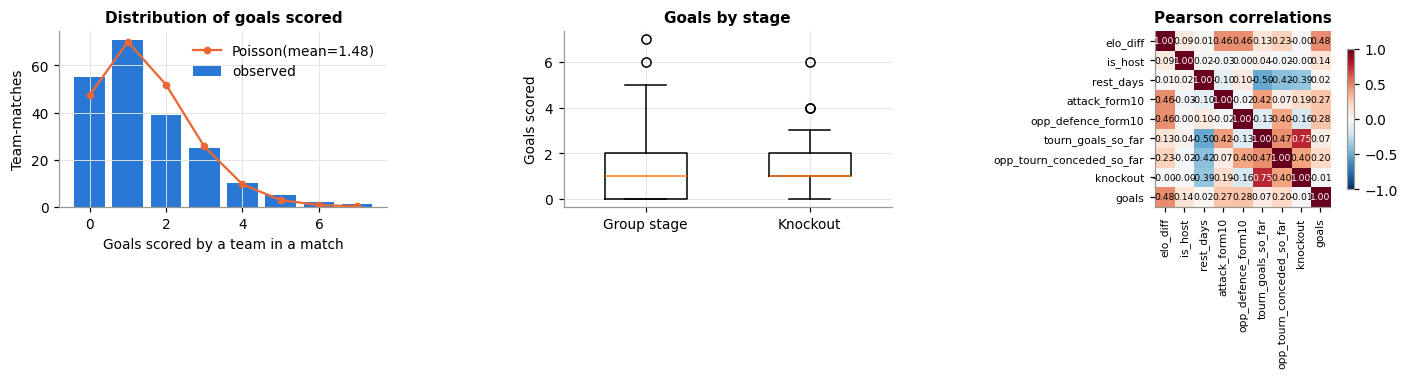

,r with goals
elo_diff,0.475
opp_defence_form10,0.282
attack_form10,0.274
opp_tourn_conceded_so_far,0.196
is_host,0.139
tourn_goals_so_far,0.072
rest_days,0.018
knockout,-0.013


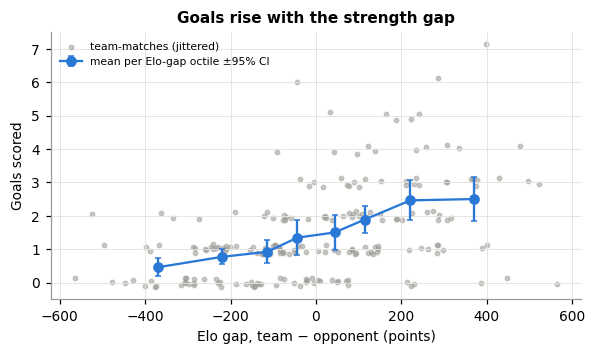

In [50]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
k = np.arange(0, reg22.goals.max() + 1)
ax[0].bar(k, [(reg22.goals == i).sum() for i in k], color=COL["blue"], label="observed")
ax[0].plot(k, 208 * stats.poisson.pmf(k, mean_g), "o-", color=COL["orange"], ms=4, label=f"Poisson(mean={mean_g:.2f})")
ax[0].set(title="Distribution of goals scored", xlabel="Goals scored by a team in a match", ylabel="Team-matches"); ax[0].legend()
ax[1].boxplot([reg22.goals[reg22.knockout == 0], reg22.goals[reg22.knockout == 1]], tick_labels=["Group stage", "Knockout"], widths=.5)
ax[1].set(title="Goals by stage", ylabel="Goals scored")
cm22 = reg22[X22 + [TARGET22]].corr()
im = ax[2].imshow(cm22, cmap="RdBu_r", vmin=-1, vmax=1)
ax[2].set_xticks(range(len(cm22)), cm22.columns, rotation=90, fontsize=7); ax[2].set_yticks(range(len(cm22)), cm22.columns, fontsize=7)
for i in range(len(cm22)):
    for j in range(len(cm22)):
        ax[2].text(j, i, f"{cm22.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(cm22.iloc[i, j]) > .6 else "black")
ax[2].set_title("Pearson correlations"); ax[2].grid(False); fig.colorbar(im, ax=ax[2], shrink=.8)
fig.tight_layout(); fig.savefig(FIG / "eda22_overview.png"); plt.show()
display(cm22[TARGET22].drop(TARGET22).sort_values(key=abs, ascending=False).to_frame("r with goals"))

fig, ax = plt.subplots(figsize=(5.5, 3.3))
binned = reg22.groupby(pd.qcut(reg22.elo_diff, 8), observed=True).agg(x=("elo_diff", "mean"), y=("goals", "mean"), se=("goals", "sem"))
ax.scatter(reg22.elo_diff, reg22.goals + np.random.default_rng(2).uniform(-.15, .15, 208), s=8, color=COL["grey"], alpha=.5, label="team-matches (jittered)")
ax.errorbar(binned.x, binned.y, yerr=1.96 * binned.se, fmt="o-", color=COL["blue"], capsize=2, label="mean per Elo-gap octile ±95% CI")
ax.set(xlabel="Elo gap, team − opponent (points)", ylabel="Goals scored", title="Goals rise with the strength gap"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "eda22_scatter.png"); plt.show()

In [51]:
section(11)
MODELS22 = {
    "Baseline (training mean)": plain(DummyRegressor(strategy="mean")),
    "OLS linear regression": plain(LinearRegression()),
    "OLS clipped at 0": plain(ClippedAtZero()),
    "Ridge regression": tuned(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": ALPHAS}),
    "Poisson regression": tuned(make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000)),
                                {"poissonregressor__alpha": np.logspace(-4, 0, 9)}),
}
Xd22, yd22, gd22 = dev22[X22], dev22[TARGET22], dev22.match_id.values
cv22, cvsum22 = repeated_cv(MODELS22, Xd22, yd22, gd22)
cvsum22.insert(0, "n dev rows", len(dev22))
display(cvsum22)
SELECTED22, BEST_CV22 = choose(cvsum22, list(MODELS22))
print(f"Lowest CV RMSE: {BEST_CV22}.  Selected by the one-SE simplicity rule: {SELECTED22}")

,n dev rows,MAE,RMSE,RMSE_SE,R2
model,,,,,
Baseline (training mean),164,1.126,1.403,0.042,-0.081
OLS linear regression,164,0.956,1.260,0.037,0.091
OLS clipped at 0,164,0.952,1.258,0.037,0.095
Ridge regression,164,0.942,1.242,0.037,0.133
Poisson regression,164,0.942,1.254,0.038,0.123


Lowest CV RMSE: Ridge regression.  Selected by the one-SE simplicity rule: OLS linear regression


## 12. Task 2.2 – evaluation on held-out matches


### 12.2 Interpreting OLS and Poisson (fitted on the development set)
The two rows of a match are related: they share referee, weather and game state. Standard errors are therefore **clustered by match**. Poisson coefficients are shown as **rate ratios**: a value of 1.10 means 10% more expected goals per unit increase in the predictor.

In [53]:
ols22 = sm.OLS(yd22, sm.add_constant(Xd22)).fit(cov_type="cluster", cov_kwds={"groups": gd22})
pois22 = sm.GLM(yd22, sm.add_constant(Xd22), family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": gd22})
coef22 = pd.DataFrame({"OLS coef": ols22.params, "OLS p": ols22.pvalues,
                       "Poisson rate ratio": np.exp(pois22.params), "RR 95% low": np.exp(pois22.conf_int()[0]),
                       "RR 95% high": np.exp(pois22.conf_int()[1]), "Poisson p": pois22.pvalues})
display(coef22)
disp22 = pois22.pearson_chi2 / pois22.df_resid
print(f"OLS R² = {ols22.rsquared:.3f} (adj {ols22.rsquared_adj:.3f}); Poisson Pearson dispersion = {disp22:.2f} "
      "(≈1 means the Poisson variance assumption is reasonable)")
vif22 = pd.Series([variance_inflation_factor(sm.add_constant(Xd22).values, i + 1) for i in range(8)], index=X22, name="VIF")
display(vif22.to_frame().T)

,OLS coef,OLS p,Poisson rate ratio,RR 95% low,RR 95% high,Poisson p
const,0.255,0.612,0.527,0.269,1.032,0.062
elo_diff,0.002,0.000,1.001,1.001,1.002,0.000
is_host,0.866,0.057,1.724,1.130,2.631,0.011
rest_days,0.018,0.744,1.017,0.948,1.091,0.634
attack_form10,0.412,0.049,1.330,1.032,1.714,0.027
opp_defence_form10,0.318,0.252,1.269,0.870,1.851,0.216
tourn_goals_so_far,-0.078,0.157,0.953,0.888,1.023,0.185
opp_tourn_conceded_so_far,0.081,0.257,1.048,0.962,1.142,0.281
knockout,-0.040,0.886,0.988,0.657,1.487,0.955


OLS R² = 0.297 (adj 0.261); Poisson Pearson dispersion = 0.89 (≈1 means the Poisson variance assumption is reasonable)


,elo_diff,is_host,rest_days,attack_form10,opp_defence_form10,tourn_goals_so_far,opp_tourn_conceded_so_far,knockout
VIF,1.863,1.087,1.655,1.710,1.952,2.516,2.087,1.706


## 13. Model comparison and interpretation

In [55]:
section(13)
summary = pd.concat({"Task 2.1 – goal difference (22 test matches)": test_tab21[["MAE", "RMSE", "R2", "selected"]],
                     "Task 2.2 – goals scored (44 test rows)": test_tab22[["MAE", "RMSE", "R2", "selected"]]})
display(summary)

# Cross-task check: does predicting each team's goals (2.2) and subtracting give a better goal difference than 2.1?
t = test22.assign(p=pred22[SELECTED22])
gd_from_22 = t.pivot_table(index="match_id", columns=t.row_id.str[-1], values="p")
gd_from_22 = (gd_from_22["A"] - gd_from_22["B"]).reindex(test21.match_id).values
cross = pd.DataFrame({f"2.1 {SELECTED21} (direct)": metrics(test21[TARGET21], pred21[SELECTED21]),
                      f"2.2 {SELECTED22}: goals A − goals B": metrics(test21[TARGET21], gd_from_22)}).T
display(cross)

MAE  RMSE     R2 selected
Task 2.1 – goal difference (22 test matches) Baseline (training mean) 1.466 1.768 -0.166         
                                             OLS linear regression    1.251 1.542  0.112         
                                             Ridge regression         1.243 1.553  0.099      Yes
                                             Random forest            1.069 1.365  0.305         
Task 2.2 – goals scored (44 test rows)       Baseline (training mean) 1.065 1.324 -0.002         
                                             OLS linear regression    0.945 1.367 -0.068      Yes
                                             OLS clipped at 0         0.936 1.356 -0.052         
                                             Ridge regression         0.916 1.294  0.044         
                                             Poisson regression       0.924 1.253  0.102

,MAE,RMSE,R2
2.1 Ridge regression (direct),1.243,1.553,0.099
2.2 OLS linear regression: goals A − goals B,1.145,1.424,0.244
